In [1]:

import os
import json
import joblib
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')


In [2]:
d=pd.read_csv("C:\\Users\\LENOVO\\Desktop\\Mlops\\churn_prediction\\data\\raw\\churn.csv")
print(d.shape)
print(d.head)
print(d.dtypes)


(7043, 21)
<bound method NDFrame.head of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service        

In [4]:
# Check target distribution
print("--- Churn Distribution ---")
print(d["Churn"].value_counts())

class_distribution = d["Churn"].value_counts(normalize=True) * 100
print("\n--- Churn Percentages ---")
print(class_distribution)

--- Churn Distribution ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64

--- Churn Percentages ---
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


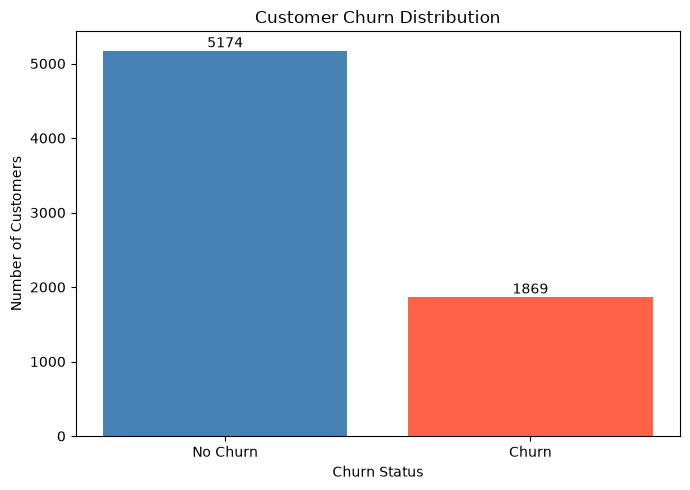

In [5]:
# Plot churn distribution
churn_counts = d["Churn"].value_counts()
churn_labels = ["No Churn", "Churn"]

plt.figure(figsize=(7, 5))
bars = plt.bar(churn_labels, churn_counts.values, color=["steelblue", "tomato"])

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [6]:
blank_totalcharges = d[
    d["TotalCharges"].str.strip() == ""
]
blank_totalcharges

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [7]:
# Handle blank strings in TotalCharges by coercing to NaN and filling with 0
d['TotalCharges'] = pd.to_numeric(d['TotalCharges'], errors='coerce').fillna(0)

# Drop redundant ID column
if 'customerID' in d.columns:
    df = d.drop('customerID', axis=1)

# Encode Target Variable (Yes -> 1, No -> 0)
d['Churn'] = d['Churn'].apply(lambda x: 1 if str(x).strip().lower() == "yes" else 0) 

# Separate features and target
X = d.drop('Churn', axis=1)
y = d['Churn'] 

print("Data cleaning complete!")

Data cleaning complete!


In [10]:
# 1. Train-Test Split (Splitting first to avoid data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Separate Column Types
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

# 3. Scale Numerical Features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train[num_cols])
x_test_scaled = scaler.transform(X_test[num_cols])

# 4. One-Hot Encode Categorical Features
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
x_train_encoded = ohe.fit_transform(X_train[cat_cols])
x_test_encoded = ohe.transform(X_test[cat_cols])

# 5. Combine Features using np.hstack
X_train_final = np.hstack((x_train_scaled, x_train_encoded))
X_test_final = np.hstack((x_test_scaled, x_test_encoded))


# Save Processed Data Arrays 
np.save('../data/processed/X_train_final.npy', X_train_final)
np.save('../data/processed/X_test_final.npy', X_test_final)
np.save('../data/processed/y_train.npy', y_train.values) 
np.save('../data/processed/y_test.npy', y_test.values)

# Save Preprocessors
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(ohe, '../models/ohe.pkl')

# Generate and Save Metadata
metadata = {
    "dataset_name": "Telco Customer Churn",
    "train_shape": X_train_final.shape,
    "test_shape": X_test_final.shape,
    "numerical_features": list(num_cols),
    "categorical_features": list(cat_cols)
}
with open('../data/processed/dataset_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)

print("Data split, engineered, and immediately saved to disk along with scaler, encoder, and metadata!")

Data split, engineered, and immediately saved to disk along with scaler, encoder, and metadata!


In [ ]:
def evaluate_and_store_metrics(model, name, X_test, y_test, results_dict, roc_dict):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] # Probabilities for the positive class (Churn=1)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print(f"--- {name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f} ")
    print(f"F1-Score : {f1:.4f}\n")
    
    results_dict[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1}
    
    # Store ROC data
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    roc_dict[name] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}

In [ ]:
metrics_results = {}
roc_data = {}

# Define Models using class_weight='balanced'
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced')
}

print("==========================================")
print("MODEL EVALUATION")
print("==========================================\n")

# Initialize tracking variables for the tournament
best_recall = 0
best_model_name = ""
best_model = None

for model_name, model in models.items():
    # Train and evaluate
    model.fit(X_train_final, y_train)
    evaluate_and_store_metrics(model, model_name, X_test_final, y_test, metrics_results, roc_data)
    
    # Programmatically compare results to find the best model based on Recall
    current_recall = metrics_results[model_name]['Recall']
    if current_recall > best_recall:
        best_recall = current_recall
        best_model_name = model_name
        best_model = model

# ==========================================
# MODEL EXPORT & ERROR ANALYSIS (TASK 2)
# ==========================================
print("==========================================")
print(f"Best Model: {best_model_name} (Recall: {best_recall:.4f})")
print("==========================================")

# Save the best model dynamically using its name
file_name = best_model_name.replace(" ", "_").lower()
joblib.dump(best_model, f'../models/{file_name}_baseline.pkl')
print(f"{best_model_name} serialized and saved to models folder!")

# Perform Error Analysis immediately using the dynamic best model
predictions = best_model.predict(X_test_final)
errors_df = X_test.copy()
errors_df['Actual_Churn'] = y_test
errors_df['Predicted_Churn'] = predictions

# Isolate errors
false_negatives = errors_df[(errors_df['Actual_Churn'] == 1) & (errors_df['Predicted_Churn'] == 0)]
false_positives = errors_df[(errors_df['Actual_Churn'] == 0) & (errors_df['Predicted_Churn'] == 1)]

false_negatives.to_csv('../outputs/false_negatives.csv', index=False)
false_positives.to_csv('../outputs/false_positives.csv', index=False)
print("Error analysis isolated and saved to outputs folder!")

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)

plt.title(f'Confusion Matrix - {best_model_name}')
plt.tight_layout()
plt.show()

In [ ]:
# Plot ROC-AUC curves for all trained models
plt.figure(figsize=(9, 6))

for model_name, roc_info in roc_data.items():
    plt.plot(
        roc_info['fpr'],
        roc_info['tpr'],
        linewidth=2,
        label=f"{model_name} (AUC = {roc_info['auc']:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curves for All Models')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()